# Focusing light through a scattering wall: wavefront shaping

A sheet of white paper, a layer of paint or a few hundred micrometres of
tissue scramble any beam into a **speckle** pattern: light is not absorbed,
it is scattered so many times that every point behind the wall receives a
random sum of contributions from every point of the incident wavefront. A
lens behind such a wall cannot focus the light, and it was long taken for
granted that the information was lost.

It is not. Without absorption and as long as nothing moves, the medium is a
linear, deterministic system. Split the incident wavefront into $N$
segments with a spatial light modulator (SLM); the field in one point
behind the wall is

$$E_m = \sum_{n=1}^{N} t_{mn}\, A_n e^{i\phi_n},$$

with the elements $t_{mn}$ of the **transmission matrix** (TM). For a
random medium the $t_{mn}$ are random complex numbers, which is why a flat
wavefront ($\phi_n = 0$) gives speckle. Setting $\phi_n = -\arg t_{mn}$
makes all $N$ contributions arrive in phase, and the intensity in point $m$
grows from the mean speckle intensity $\sum_n |t_{mn}|^2$ to
$\left(\sum_n |t_{mn}|\right)^2$: a focus behind the wall. Vellekoop and
Mosk showed this in 2007 with a layer of white paint, without knowing the
TM: they optimized the phases of the SLM one segment at a time, guided only
by the intensity in the target. For Rayleigh distributed $|t_{mn}|$ the
**enhancement** over the mean speckle is

$$\eta = \frac{\left(\sum_n |t_{mn}|\right)^2}{\sum_n |t_{mn}|^2} \approx \frac{\pi}{4}(N - 1) + 1.$$

This notebook builds a scattering wall, finds a focus behind it and checks
the numbers against this theory:

1. speckle behind a diffuser: the exponential intensity statistics and the
   grain size,
2. the transmission matrix: a random matrix with circular Gaussian elements
   and Marchenko-Pastur singular values,
3. focusing with a known TM: $\eta$ against $N$ for phase, amplitude and
   phase, quantized phase and binary amplitude modulation,
4. iterative wavefront shaping with feedback from one detector (Vellekoop
   and Mosk 2008): stepwise and continuous sequential, partitioning, with
   noise and with a medium that changes,
5. measuring the TM with phase-stepping interferometry (Popoff et al.
   2010): canonical and Hadamard bases under noise, several foci, a
   Gerchberg-Saxton loop through the TM,
6. a thick slab of random medium with the wave propagation method (WPM):
   light finding its way to the focus, digital phase conjugation and the
   optical memory effect, which shrinks with the thickness,
7. a multimode fibre built from the LP modes of notebook 09: focusing at the
   far end, where the number of modes limits the contrast.

The tools are in `pyoptics.wavefront_shaping` (random screens, SLM segments,
TMs, the algorithms and the theory). The thick slab uses `pyoptics.wpm`,
the fibre `pyoptics.modes`, the pattern projection the Gerchberg-Saxton loop
of `pyoptics.ifta`. Phase retrieval and beam shaping without a scatterer are
in notebooks [28](28_phase_retrieval.ipynb) and [30](30_IFTA.ipynb), the WPM
in [05](05_WPM.ipynb), fibre modes in [09](09_mode_analysis.ipynb).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j1

from pyoptics import fft as pfft
from pyoptics import modes, sketch
from pyoptics import wavefront_shaping as ws
from pyoptics.utils import grid2d
from pyoptics.propagators import rayleigh_sommerfeld_I_TF, rayleigh_sommerfeld_I_TF_planes
from pyoptics.wpm import wpm_propagate_z

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
t_start = time.time()

WL = 0.633                      # HeNe (µm)
F = 100e3                       # focal length of the lens in front of the camera (µm)
NG, DX = 512, 4.0               # samples and spacing in the diffuser plane (µm)
D = 1024.0                      # side of the square SLM area imaged onto the diffuser
x, y, X, Y = grid2d(-NG*DX/2, NG*DX/2, -NG*DX/2, NG*DX/2, NG)
DX_CAM = WL*F/(NG*DX)           # camera sampling (31 µm)
GRAIN = WL*F/D                  # speckle grain: two camera samples (62 µm)
xc = (np.arange(NG) - NG//2)*DX_CAM/1e3        # camera coordinates (mm)
aperture = (np.abs(X) < D/2) & (np.abs(Y) < D/2)


def camera(u):
    """Field in the back focal plane of the lens behind the diffuser (stacks allowed)."""
    return np.fft.fftshift(pfft.fft2(np.fft.ifftshift(u, axes=(-2, -1)), axes=(-2, -1)),
                           axes=(-2, -1))


def extent(c):
    d = c[1] - c[0]
    return [c[0] - d/2, c[-1] + d/2, c[0] - d/2, c[-1] + d/2]


def show(ax, img, ext, title, cmap="inferno", **kwargs):
    im = ax.imshow(img, extent=ext, cmap=cmap, **kwargs)
    ax.set_title(title)
    return im

## The setup

A collimated laser beam falls onto a phase-only SLM, whose $N$ segments
(macro pixels) are imaged onto the front face of the scattering wall. A lens
behind the wall images its far field onto a camera; any pixel of the camera
can be the target, and a single photodiode behind a pinhole would do for the
feedback algorithms. The model of the wall is a ground glass diffuser: a
random phase screen $\varphi(x, y)$ with Gaussian statistics, standard
deviation $2\pi$ and correlation length $\ell = 8$ µm, so that there is no
unscattered light left. The field on the camera is the Fourier transform of
the field behind the diffuser, $E(\mathbf{k}) = \mathcal{F}\{s(x, y)\,
e^{i\varphi(x, y)}\}$ with the SLM field $s$. The illuminated square has a
side of $D = 1.024$ mm; on the camera ($f = 100$ mm) one speckle grain is
$\lambda f/D = 62$ µm, two camera samples.

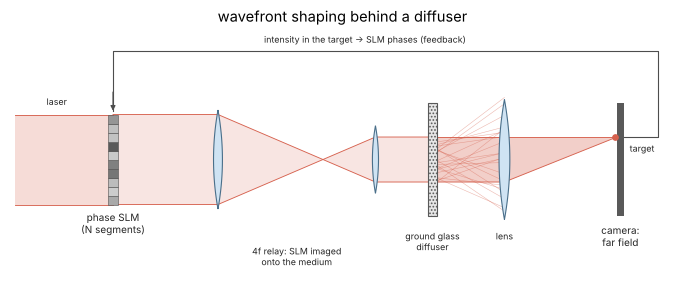

In [2]:
fig, ax = plt.subplots(figsize=(14, 4.2))
sketch.wavefront_shaping_setup(ax, medium="diffuser", title="wavefront shaping behind a diffuser")

## 1. Speckle behind a diffuser

Without the diffuser the lens focuses the square beam into a sinc² spot.
With it, the light spreads over an angle of about $\lambda/\ell$ and forms
fully developed speckle: a random sum of many phasors, i.e. a circular
Gaussian field. Its intensity has the exponential distribution
$p(I) = e^{-I/\langle I\rangle}/\langle I\rangle$ with a contrast
$\sigma_I/\langle I\rangle = 1$, and the darkest value is the most likely.
The size of a grain is set by the illuminated aperture, not by the
diffuser: the intensity autocorrelation is $1 + |\mu|^2$, with $\mu$ the
normalized Fourier transform of the intensity in the aperture, here
$\mathrm{sinc}(D\,\Delta x/\lambda f)\,\mathrm{sinc}(D\,\Delta y/\lambda f)$
(the van Cittert-Zernike theorem in its speckle form).

speckle contrast sigma_I/<I> = 0.994 (theory 1)
unscattered light in the zero order: 1.4e-05 of the clear-aperture peak


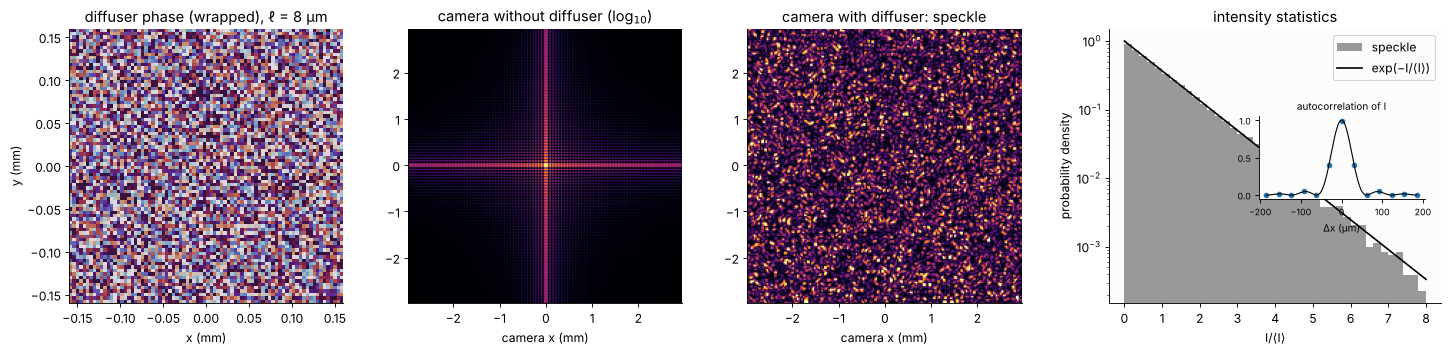

In [3]:
ELL, SIGMA = 8.0, 2*np.pi
phase_screen = ws.random_phase_screen((NG, NG), ELL, SIGMA, dx=DX, rng=1)
diffuser = np.exp(1j*phase_screen)

I_clear = np.abs(camera(aperture.astype(complex)))**2
I_speckle = np.abs(camera(aperture*diffuser))**2
I_mean = I_speckle[NG//2 - 128:NG//2 + 128, NG//2 - 128:NG//2 + 128].mean()
I_clear, I_speckle = I_clear/I_mean, I_speckle/I_mean

c = NG//2
patch = I_speckle[c - 128:c + 128, c - 128:c + 128]
print("speckle contrast sigma_I/<I> = {:.3f} (theory 1)".format(patch.std()/patch.mean()))
print("unscattered light in the zero order: {:.1e} of the clear-aperture peak".format(
    I_speckle[c, c]/I_clear[c, c]))

# intensity autocorrelation over the central 256 x 256 samples
dI = patch/patch.mean() - 1
corr = np.fft.fftshift(np.real(np.fft.ifft2(np.abs(np.fft.fft2(dI))**2)))/dI.size
shift = (np.arange(256) - 128)*DX_CAM
fig, ax = plt.subplots(1, 4, figsize=(18, 4.3), layout="constrained")
z = 40
show(ax[0], np.angle(diffuser[c - z:c + z, c - z:c + z]), [x[c - z]/1e3, x[c + z]/1e3]*2,
     "diffuser phase (wrapped), ℓ = 8 µm", cmap="twilight")
ax[0].set_xlabel("x (mm)"); ax[0].set_ylabel("y (mm)")
zc = 96
ext_c = extent(xc[c - zc:c + zc])
show(ax[1], np.log10(I_clear[c - zc:c + zc, c - zc:c + zc] + 1e-3), ext_c,
     "camera without diffuser (log$_{10}$)", vmin=-3)
show(ax[2], I_speckle[c - zc:c + zc, c - zc:c + zc], ext_c, "camera with diffuser: speckle", vmax=4)
for a in ax[1:3]:
    a.set_xlabel("camera x (mm)")
bins = np.linspace(0, 8, 41)
ax[3].hist(patch.ravel()/patch.mean(), bins=bins, density=True, color="0.6", label="speckle")
ax[3].plot(bins, np.exp(-bins), "k-", label="exp(−I/⟨I⟩)")
ax[3].set_yscale("log"); ax[3].set_xlabel("I/⟨I⟩"); ax[3].set_ylabel("probability density")
ax[3].legend(); ax[3].set_title("intensity statistics")
ins = ax[3].inset_axes([0.45, 0.38, 0.5, 0.3])
ds = np.linspace(-6*DX_CAM, 6*DX_CAM, 200)
ins.plot(shift[128 - 6:128 + 7], corr[128, 128 - 6:128 + 7], "o", ms=4, color="C0", label="speckle")
ins.plot(ds, np.sinc(ds*D/(WL*F))**2, "k-", lw=1, label="sinc²")
ins.set_xlabel("Δx (µm)", fontsize=9); ins.set_title("autocorrelation of I", fontsize=9)
ins.tick_params(labelsize=8)

The speckle is fully developed (contrast 1, exponential statistics over
three decades) and the grain has exactly the shape of the diffraction
spot of the clear aperture. The diffuser is strong enough that the
unscattered (ballistic) light is negligible: the zero order that would
dominate a weak diffuser is gone.

## 2. The transmission matrix

The field on the camera is linear in the SLM field, so switching on one
segment at a time gives one column of the TM. With $32 \times 32$ segments
of $32 \times 32$ µm² each the matrix to the $64 \times 64$ camera samples
around the axis has $4096 \times 1024$ elements. Coarser SLMs need no new
calculation: a coarse segment is the sum of the fine segments it covers, and
its column the sum of their columns.

Each element is the sum of the light of one segment (about 16 correlation
cells of the diffuser) sent into one direction: a circular Gaussian random
number. The TM as a whole is then a random matrix, and its singular values
follow the **Marchenko-Pastur law** of random matrix theory (the
quarter-circle law for a square matrix), as Popoff et al. found
experimentally. This only holds for camera samples that are uncorrelated,
i.e. one per speckle grain: with all samples (two per grain and axis) the
rows are correlated, and the singular values spread.

TM: 4096 x 1024 in 6.6 s


<|t|>^2/<|t|^2> = 0.7822 (Rayleigh: pi/4 = 0.7854)


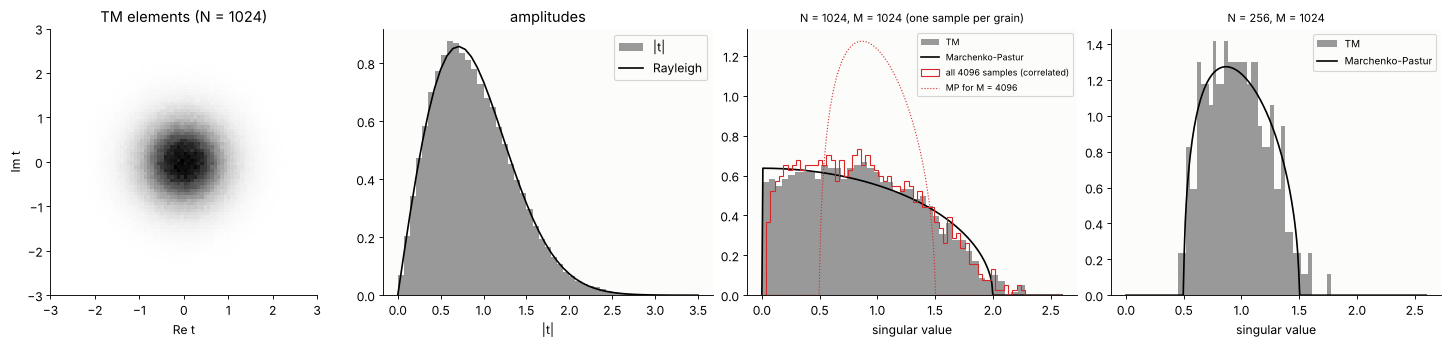

In [4]:
t0 = time.time()
ROI = 32                                       # camera window: 64 x 64 samples = 32 x 32 grains
roi_mask = np.zeros((NG, NG), bool)
roi_mask[c - ROI:c + ROI, c - ROI:c + ROI] = True
labels32 = ws.segment_labels(x, y, 32, D)
T_fine = ws.transmission_matrix(lambda u: camera(u*diffuser), labels32, output=roi_mask, batch=64)
T_fine /= np.sqrt(np.mean(np.abs(T_fine)**2))          # <|t|^2> = 1
print("TM: {} x {} in {:.1f} s".format(*T_fine.shape, time.time() - t0))


def coarse_tm(T, n, n_fine=32):
    """TM for n x n segments from the TM of n_fine x n_fine segments."""
    f = n_fine//n
    iy, ix = np.divmod(np.arange(n_fine**2), n_fine)
    S = np.zeros((n_fine**2, n*n))
    S[np.arange(n_fine**2), (iy//f)*n + ix//f] = 1.0
    return T @ S


grain_rows = (np.arange(2*ROI)[:, None] % 2 == 0) & (np.arange(2*ROI)[None, :] % 2 == 0)
grain_rows = np.nonzero(grain_rows.ravel())[0]          # one sample per grain: 1024 rows
TM = {n: coarse_tm(T_fine, n) for n in (2, 4, 8, 16, 32)}
for n in TM:
    TM[n] /= np.sqrt(np.mean(np.abs(TM[n])**2))

t_all = T_fine[grain_rows].ravel()
fig, ax = plt.subplots(1, 4, figsize=(18, 4.2), layout="constrained")
ax[0].hist2d(t_all.real, t_all.imag, bins=80, range=[[-3, 3], [-3, 3]], cmap="Greys")
ax[0].set_aspect("equal"); ax[0].set_xlabel("Re t"); ax[0].set_ylabel("Im t")
ax[0].set_title("TM elements (N = 1024)")
b = np.linspace(0, 3.5, 50)
ax[1].hist(np.abs(t_all), bins=b, density=True, color="0.6", label="|t|")
ax[1].plot(b, 2*b*np.exp(-b**2), "k-", label="Rayleigh")
ax[1].set_xlabel("|t|"); ax[1].legend(); ax[1].set_title("amplitudes")
print("<|t|>^2/<|t|^2> = {:.4f} (Rayleigh: pi/4 = {:.4f})".format(np.mean(np.abs(t_all))**2, np.pi/4))

s = np.linspace(0, 2.6, 300)
for a, (T, ratio, title) in zip(ax[2:], [(TM[32][grain_rows], 1.0, "N = 1024, M = 1024 (one sample per grain)"),
                                        (TM[16][grain_rows], 0.25, "N = 256, M = 1024")]):
    sv = np.linalg.svd(T/np.sqrt(T.shape[0]), compute_uv=False)
    a.hist(sv, bins=40, density=True, color="0.6", label="TM")
    a.plot(s, ws.marchenko_pastur_pdf(s, ratio), "k-", label="Marchenko-Pastur")
    a.set_xlabel("singular value"); a.set_title(title, fontsize=10)
sv_all = np.linalg.svd(TM[32]/np.sqrt(TM[32].shape[0]), compute_uv=False)
ax[2].hist(sv_all, bins=60, density=True, histtype="step", color="C3",
           label="all 4096 samples (correlated)")
ax[2].plot(s, ws.marchenko_pastur_pdf(s, 0.25), "C3:", lw=1, label="MP for M = 4096")
ax[2].legend(fontsize=8)
ax[3].legend(fontsize=9)

With one camera sample per grain the singular values of the simulated TM
sit on the quarter circle (square TM) and on the Marchenko-Pastur
distribution for $N/M = 1/4$. Using all samples of the camera (red) does
not make the matrix four times taller in the sense of random matrix theory:
neighbouring samples within a grain are correlated, the matrix has only
about 1024 independent rows, and its singular values are far from the law
for $4096 \times 1024$ independent elements. The amplitudes are Rayleigh
distributed, so $\langle|t|\rangle^2/\langle|t|^2\rangle = \pi/4$, the
factor that appears in the enhancement.

## 3. Focusing with a known transmission matrix

With the TM row $t_n$ of a target sample the best SLM settings follow at
once (`ws.phase_conjugation()`):

- **amplitude and phase** $A_n e^{i\phi_n} \propto t_n^*$ (normalized to
  the same input power): $\eta = N$ exactly,
- **phase only** $\phi_n = -\arg t_n$: $\eta = 1 + (N-1)\pi/4$,
- **$P$ phase levels**: the residual phase error is uniform in
  $\pm\pi/P$, which costs $\mathrm{sinc}^2(\pi/P)$:
  $\eta = 1 + (N-1)\frac{\pi}{4}\mathrm{sinc}^2(\pi/P)$, i.e.
  $1 + (N-1)/\pi$ for a binary phase SLM,
- **binary amplitude** (a digital micromirror device): switch on the
  segments with $\mathrm{Re}(t_n e^{-i\theta}) > 0$, half of them, which
  gives $\eta = 1 + (N-1)/2\pi$ against the speckle of the same input
  power (Akbulut et al. 2011).

`ws.enhancement()` divides the focus by the mean speckle intensity of the
same input power, $\sum_n|t_n|^2 \cdot \sum_n|A_n|^2/N$ (the average over
random SLM phases).

enhancement in the target: 819 (from the TM: 803, theory 804)
mean background around the focus / mean speckle of random SLM settings: 0.623
power in the focus (3 x 3 samples): 1.00% of the light on the camera


Text(0.5, 1.0, 'cut through the focus')

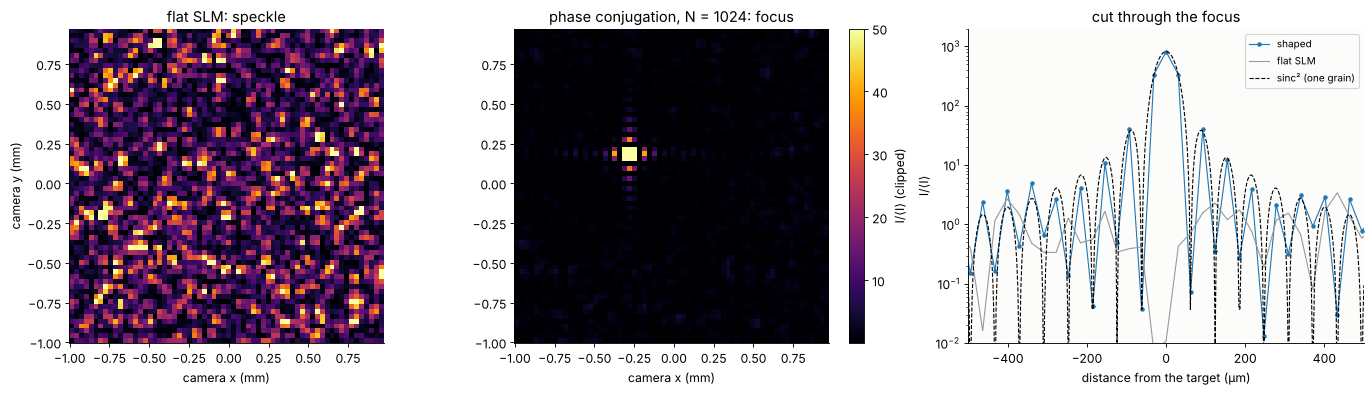

In [5]:
target = (ROI + 6, ROI - 9)                       # a sample 6 grains off the axis (in the 64 x 64 window)
target_row = target[0]*2*ROI + target[1]
values = ws.phase_conjugation(TM[32][target_row])
I_flat = np.abs(camera(aperture*diffuser))**2
I_focus = np.abs(camera(ws.segment_field(values, labels32)*diffuser))**2
# reference: the mean speckle over random SLM settings (their segment edges diffract like the shaped one)
rng_ref = np.random.default_rng(11)
I_rand = np.mean([np.abs(camera(ws.segment_field(np.exp(2j*np.pi*rng_ref.random(1024)), labels32)*diffuser))**2
                  for _ in range(16)], axis=0)
I_ref = I_rand[roi_mask].mean()
print("enhancement in the target: {:.0f} (from the TM: {:.0f}, theory {:.0f})".format(
    I_focus[roi_mask][target_row]/I_ref, ws.enhancement(TM[32][target_row], values),
    ws.expected_enhancement(1024)))
ring = roi_mask.copy()
ring[c - ROI + target[0] - 3:c - ROI + target[0] + 4, c - ROI + target[1] - 3:c - ROI + target[1] + 4] = False
print("mean background around the focus / mean speckle of random SLM settings: {:.3f}".format(
    I_focus[ring].mean()/I_rand[ring].mean()))
P_total = I_focus.sum()
P_focus = I_focus[c - ROI + target[0] - 1:c - ROI + target[0] + 2, c - ROI + target[1] - 1:c - ROI + target[1] + 2].sum()
print("power in the focus (3 x 3 samples): {:.2%} of the light on the camera".format(P_focus/P_total))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), layout="constrained")
ext_r = extent(xc[c - ROI:c + ROI])
show(ax[0], I_flat[roi_mask].reshape(2*ROI, -1)/I_ref, ext_r, "flat SLM: speckle", vmax=4)
im = show(ax[1], I_focus[roi_mask].reshape(2*ROI, -1)/I_ref, ext_r, "phase conjugation, N = 1024: focus",
          vmax=50)
fig.colorbar(im, ax=ax[1], label="I/⟨I⟩ (clipped)")
for a in ax[:2]:
    a.set_xlabel("camera x (mm)")
ax[0].set_ylabel("camera y (mm)")
row = c - ROI + target[0]
col = c - ROI + target[1]
xs_cut = (np.arange(NG) - col)*DX_CAM
ax[2].plot(xs_cut, I_focus[row]/I_ref, "o-", ms=3, lw=1, label="shaped")
ax[2].plot(xs_cut, I_flat[row]/I_ref, "-", color="0.6", lw=1, label="flat SLM")
xx = np.linspace(-500, 500, 400)
ax[2].plot(xx, I_focus[row, col]/I_ref*np.sinc(xx*D/(WL*F))**2, "k--", lw=1, label="sinc² (one grain)")
ax[2].set_xlim(-500, 500); ax[2].set_yscale("log"); ax[2].set_ylim(1e-2, 2e3)
ax[2].set_xlabel("distance from the target (µm)"); ax[2].set_ylabel("I/⟨I⟩"); ax[2].legend(fontsize=9)
ax[2].set_title("cut through the focus")

The focus is exactly one speckle grain: the wall plus lens cannot make
it smaller, because the grain is the diffraction limit of the illuminated
aperture. Its sidelobes follow the sinc² of the aperture down to the level
of the speckle. The focus collects $\eta$ times the power of one grain, out
of the many thousand grains of the scattered halo: one percent of the light
on the camera, whose total is unchanged.

The speckle around the focus is darker than the mean of random SLM
settings (0.62 in this window). This is a property of the thin diffuser:
light from one segment sent into neighbouring directions passes the same
diffuser cells, so the TM rows of nearby camera samples are correlated
element by element, up to a phase ramp across the SLM (this is the memory
effect of section 6). Around the focus the shaped field is then partly the
focus itself, shifted, whose sinc² has zeros on the grain grid; the missing
light appears further out. Behind the thick slab of section 6 this
correlation is lost.

Now $\eta$ against $N$ for the four kinds of modulation, averaged over the
1024 independent target samples:

   N      amplitude and phase            phase only          binary phase      binary amplitude


    4            4.0 (   4.0)          3.3 (   3.4)          2.0 (   2.0)          2.0 (   1.5)
   16           16.0 (  16.0)         12.8 (  12.8)          5.8 (   5.8)          4.8 (   3.4)
   64           64.0 (  64.0)         50.7 (  50.5)         21.1 (  21.1)         14.4 (  11.0)
  256          256.0 ( 256.0)        199.7 ( 201.3)         81.5 (  82.2)         48.6 (  41.6)
 1024         1024.0 (1024.0)        800.9 ( 804.5)        325.2 ( 326.6)        178.3 ( 163.8)


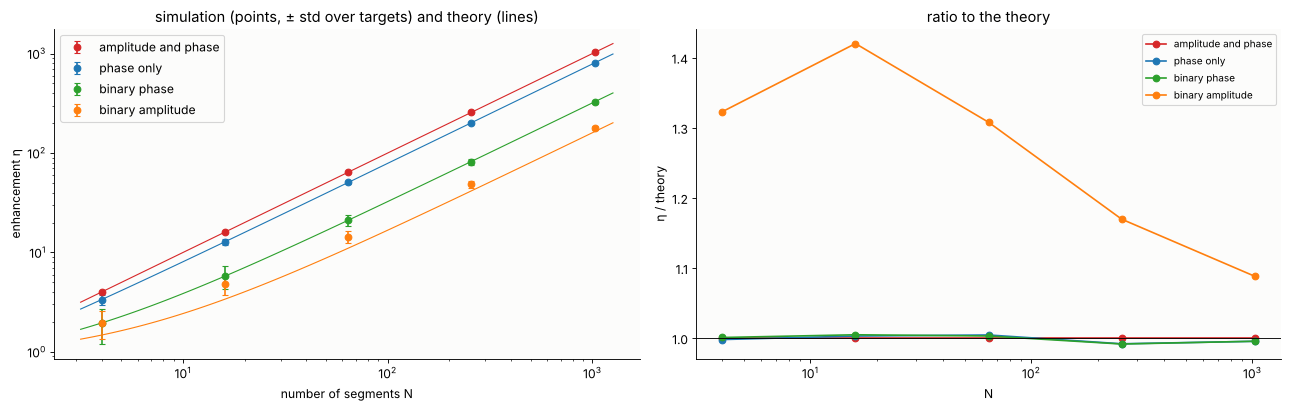

In [6]:
modulations = [("full", None, "amplitude and phase", "C3"), ("phase", None, "phase only", "C0"),
               ("phase", 2, "binary phase", "C2"), ("binary_amplitude", None, "binary amplitude", "C1")]
Ns = np.array([n*n for n in TM])
fig, ax = plt.subplots(1, 2, figsize=(16, 5), layout="constrained")
NN = np.logspace(0.5, 3.1, 100)
print("   N   " + "".join("{:>22}".format(m[2]) for m in modulations))
results = {}
for modulation, levels, name, colour in modulations:
    eta = np.array([[ws.enhancement(t, ws.phase_conjugation(t, modulation, levels))
                     for t in TM[n][grain_rows]] for n in TM])
    results[name] = eta
    ax[0].errorbar(Ns, eta.mean(1), eta.std(1), fmt="o", color=colour, capsize=3, label=name)
    ax[0].plot(NN, ws.expected_enhancement(NN, modulation, levels), "-", color=colour, lw=1)
    ax[1].plot(Ns, eta.mean(1)/ws.expected_enhancement(Ns, modulation, levels), "o-", color=colour, label=name)
for i, N in enumerate(Ns):
    print("{:5d}  ".format(N) + "".join("{:>13.1f} ({:>6.1f})".format(
        results[m[2]][i].mean(), ws.expected_enhancement(N, m[0], m[1])) for m in modulations))
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("number of segments N"); ax[0].set_ylabel("enhancement η")
ax[0].legend(); ax[0].set_title("simulation (points, ± std over targets) and theory (lines)")
ax[1].axhline(1, color="k", lw=0.8)
ax[1].set_xscale("log"); ax[1].set_xlabel("N"); ax[1].set_ylabel("η / theory")
ax[1].set_title("ratio to the theory"); ax[1].legend(fontsize=9)

The simulated enhancements agree with the theory to about one percent for
the phase modulations from 16 segments on (the table gives simulation and
theory side by side). Full control of amplitude and phase gives exactly
$N$ by construction; phase-only loses only the factor $\pi/4$, which is why
almost all experiments use phase-only SLMs. A binary phase SLM keeps $1/\pi$
of $N$, a DMD with binary amplitude $1/2\pi$, but a DMD switches some
thousand times faster than a liquid crystal SLM. For binary amplitude the
simulation lies above the half-plane theory for small $N$:
`phase_conjugation()` picks the best of all half planes $\theta$, which
adds a fluctuation term that decays as $1/\sqrt{N}$ (still 9 % at
$N = 1024$).

The spread from target to target is the statistics of $\sum_n |t_n|$: its
relative standard deviation falls as $1/\sqrt{N}$.

## 4. Iterative wavefront shaping: feedback from one detector

An experiment does not know the TM. Vellekoop and Mosk (2007, 2008) found
the phases with nothing but the intensity in the target, measured by a
photodiode behind a pinhole. The phase of one segment is stepped through
$P$ values; the target intensity follows a cosine,
$I(\phi) = |E_\mathrm{rest} + t_n e^{i\phi}|^2$, whose maximum is where
segment $n$ is in phase with the rest. Three strategies
(`ws.stepwise_sequential()` and `ws.partitioning()`):

- **stepwise sequential (SSA)**: every segment is measured against the same
  initial speckle and all phases are set at the end of a sweep. The signal
  stays at the speckle level during the sweep, and the modulation of one
  segment is tiny, $2|E_\mathrm{rest}||t_n| \sim 2\langle I\rangle/\sqrt N$,
- **continuous sequential (CSA)**: every new phase is set at once, so the
  focus grows during the sweep and later segments are measured against a
  stronger field,
- **random partitioning (RPA)**: a random half of all segments is stepped
  together. Each step changes half the field and so gives a large signal;
  the enhancement rises fastest at the beginning but approaches the optimum
  only slowly.

The experiment is simulated through the TM row of the target (N = 256,
$P = 6$ phase steps). Noise is Gaussian with a standard deviation given in
units of the initial mean speckle intensity in the target, and a medium that
changes (living tissue, a drifting setup) is modelled by mixing a fresh
random TM into the old one at every measurement, so that the intensity
correlation decays as $e^{-k/T_p}$ after $k$ measurements (persistence
time $T_p$).

no noise                         SSA: final enhancement  191.2
no noise                         CSA: final enhancement  191.2
no noise                         RPA: final enhancement  162.0
noise 1.0 ⟨I₀⟩                   SSA: final enhancement   48.0
noise 1.0 ⟨I₀⟩                   CSA: final enhancement  139.2
noise 1.0 ⟨I₀⟩                   RPA: final enhancement  166.0


changing medium, T_p = 2000      SSA: final enhancement  121.6
changing medium, T_p = 2000      CSA: final enhancement  121.5
changing medium, T_p = 2000      RPA: final enhancement   79.6


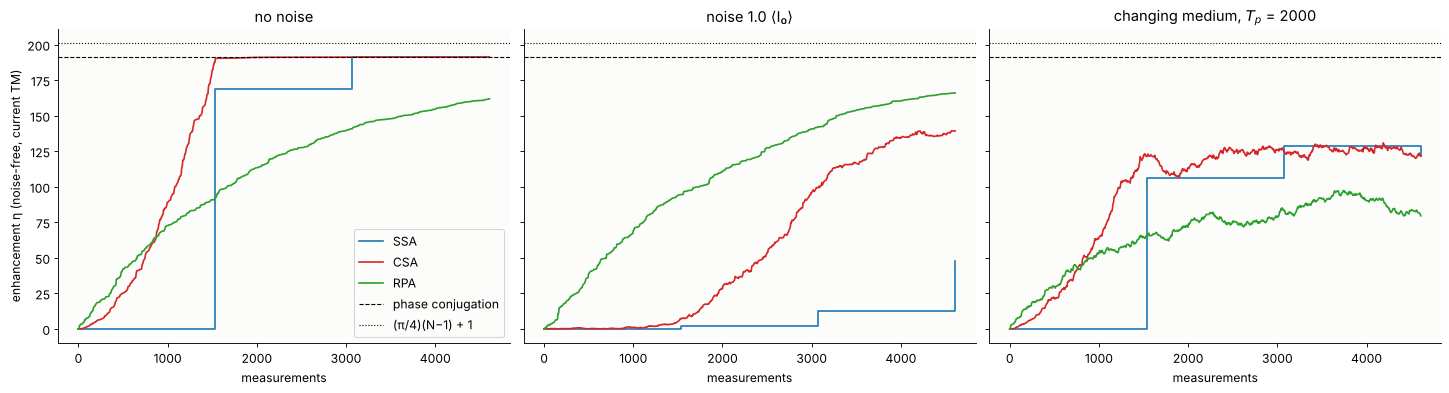

In [7]:
class Experiment:
    """Intensity in one target sample behind the medium: noise and a changing TM."""

    def __init__(self, t, noise=0.0, persistence=None, seed=0):
        self.t = np.array(t, dtype=complex)
        self.I0 = np.sum(np.abs(self.t)**2)             # mean speckle intensity in the target
        self.noise, self.persistence = noise, persistence
        self.rng = np.random.default_rng(seed)
        self.history = []

    def __call__(self, values):
        if self.persistence:
            eps = 1/self.persistence
            fresh = (self.rng.standard_normal(len(self.t)) + 1j*self.rng.standard_normal(len(self.t)))
            self.t = np.sqrt(1 - eps)*self.t + np.sqrt(eps*self.I0/len(self.t)/2)*fresh
        I = np.abs(self.t @ values)**2
        return I + self.noise*self.I0*self.rng.standard_normal()

    def record(self, values, count):
        self.history.append((count, ws.enhancement(self.t, values)))


N_IT, P = 256, 6
t_target = TM[16][target_row]
eta_opt = ws.enhancement(t_target, ws.phase_conjugation(t_target))
n_meas = 3*N_IT*P


def run(algorithm, **kwargs):
    exp = Experiment(t_target, **kwargs)
    exp.record(np.ones(N_IT), 0)
    if algorithm == "SSA":
        ws.stepwise_sequential(exp, N_IT, P, continuous=False, n_sweeps=3, callback=exp.record)
    elif algorithm == "CSA":
        ws.stepwise_sequential(exp, N_IT, P, continuous=True, n_sweeps=3, callback=exp.record)
    else:
        ws.partitioning(exp, N_IT, n_meas//P, P, rng=1, callback=exp.record)
    return np.array(exp.history)


cases = [("no noise", {}), ("noise 1.0 ⟨I₀⟩", {"noise": 1.0}),
         ("changing medium, $T_p$ = 2000", {"persistence": 2000})]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8), layout="constrained", sharey=True)
for a, (title, kwargs) in zip(ax, cases):
    for algorithm, colour in [("SSA", "C0"), ("CSA", "C3"), ("RPA", "C2")]:
        h = run(algorithm, **kwargs)
        a.plot(h[:, 0], h[:, 1], drawstyle="steps-post" if algorithm == "SSA" else "default",
               color=colour, label=algorithm)
        print("{:32s} {}: final enhancement {:6.1f}".format(title.replace("$", ""), algorithm, h[-1, 1]))
    a.axhline(eta_opt, color="k", ls="--", lw=1, label="phase conjugation")
    a.axhline(ws.expected_enhancement(N_IT), color="k", ls=":", lw=1, label="(π/4)(N−1) + 1")
    a.set_xlabel("measurements"); a.set_title(title)
ax[0].set_ylabel("enhancement η (noise-free, current TM)")
ax[0].legend()

Without noise, one sweep of SSA ($NP = 1536$ measurements) gives about
90 % of the phase-conjugation optimum and the second sweep the rest: the
cosine fit finds each phase exactly, but measured against the initial
speckle instead of the final field. CSA reaches the optimum continuously
within its first sweep. RPA rises fastest for
the first few hundred measurements and then creeps towards the optimum.

With noise as large as the mean speckle intensity in the target, the
single-segment signal $\sim 2\langle I_0\rangle/\sqrt N$ of SSA drowns:
its phases are largely random, and it ends at a quarter of the optimum even
after three sweeps, because every sweep is measured against a weak field
again. CSA recovers: as the focus grows, $|E_\mathrm{rest}|$ and with it the
signal of every further segment grow, so the later phases are measured
well and the next sweep repairs the first. RPA modulates half the field
with every step and is hardly affected (compare the printed final values).

In a changing medium the focus decays while it is being built, and all
three stay well below the optimum. Here the sequential algorithms keep the
higher enhancement: each of their measurements improves one phase for
good, while the slow final approach of RPA cannot keep up with a TM that
renews itself every 2000 measurements. Which algorithm is best therefore
depends on whether noise or decorrelation limits the experiment, and in a
changing medium on the number of segments that can be optimized within
the persistence time.

## 5. Measuring the transmission matrix

Popoff et al. (2010) measured the whole TM at once with a camera: the
central part of the SLM carries the $N$ controlled segments, the frame
around it stays flat and gives a static reference speckle $r_m$ on the
camera. For each input pattern $b_j$ the phase is stepped four times, and
in every camera sample

$$\frac{1}{4}\sum_{k=0}^{3} I_k\, e^{-i\phi_k} = r_m^*\,(T b_j)_m, \qquad I_k = |r_m + e^{i\phi_k}(T b_j)_m|^2,$$

so $4N$ camera frames give the observed TM $\mathrm{diag}(r^*)\,T$
(`ws.measure_transmission_matrix()`). The unknown reference multiplies each
row by a constant and does not matter for focusing into that sample.

Switching on one segment at a time (the canonical basis) makes the signal
tiny: one segment against a reference that carries a large fraction of the
light. In the **Hadamard basis** all segments are on in every pattern (with
phases 0 or $\pi$), the signal is $\sqrt{N}$ times larger in field, and the
noise spreads evenly over all elements when the basis is inverted. Below,
the controlled area is the inner $768 \times 768$ µm² with $16 \times 16$
segments, the frame out to 1024 µm is the reference, and the camera noise
is Gaussian with a standard deviation in units of the mean camera
intensity.

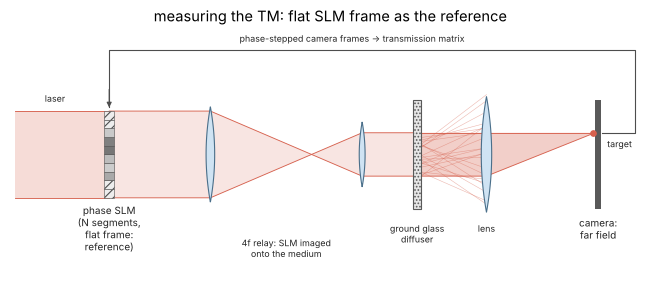

mean reference intensity / mean signal intensity: 0.77


1024 measurements; noise-free observed TM = diag(r*) T: True


canonical: η / optimum for noise [0.0, 0.01, 0.03, 0.1, 0.3, 1.0]: [1.    0.922 0.683 0.241 0.044 0.009]


hadamard : η / optimum for noise [0.0, 0.01, 0.03, 0.1, 0.3, 1.0]: [1.    0.999 0.994 0.961 0.816 0.408]


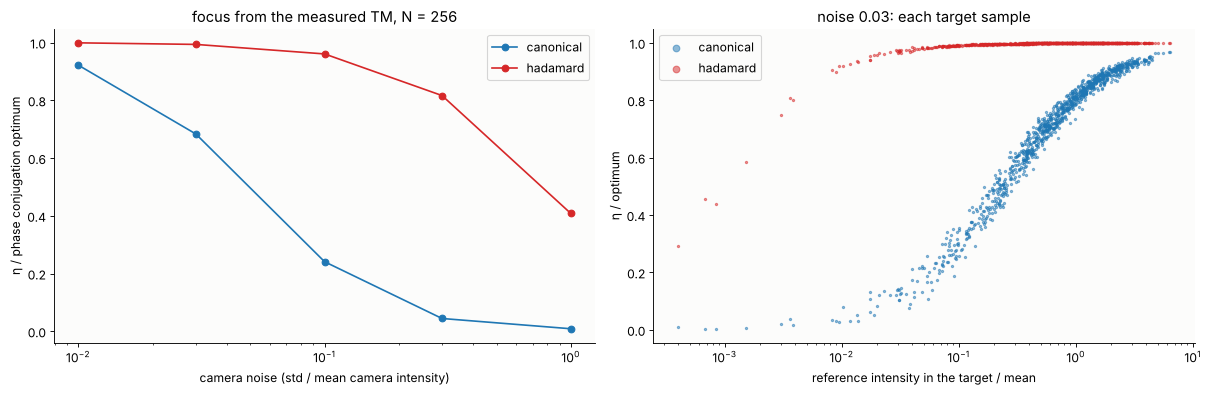

In [8]:
fig, ax = plt.subplots(figsize=(14, 4.4))
sketch.wavefront_shaping_setup(ax, medium="diffuser", reference=True,
                               title="measuring the TM: flat SLM frame as the reference")
plt.show()

D_IN, N_TM = 768.0, 256
labels_in = ws.segment_labels(x, y, 16, D_IN)
frame = aperture & (labels_in < 0)
T_in = ws.transmission_matrix(lambda u: camera(u*diffuser), labels_in, output=roi_mask, batch=64)
r_ref = camera(frame*diffuser)[roi_mask]
scale = np.sqrt(np.mean(np.abs(T_in)**2))
T_in, r_ref = T_in/scale, r_ref/scale
I_cam_mean = np.mean(np.abs(r_ref)**2) + N_TM
print("mean reference intensity / mean signal intensity: {:.2f}".format(np.mean(np.abs(r_ref)**2)/N_TM))


def tm_experiment(noise, seed=0):
    rng = np.random.default_rng(seed)
    return lambda v: np.abs(r_ref + T_in @ v)**2 + noise*I_cam_mean*rng.standard_normal(len(r_ref))


T_obs, count = ws.measure_transmission_matrix(tm_experiment(0.0), N_TM, basis="hadamard")
print("{} measurements; noise-free observed TM = diag(r*) T: {}".format(
    count, np.allclose(T_obs, np.conj(r_ref)[:, None]*T_in)))

T_in_g = T_in[grain_rows]
eta_true = np.array([ws.enhancement(t, ws.phase_conjugation(t)) for t in T_in_g])
noises = [0.0, 0.01, 0.03, 0.1, 0.3, 1.0]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
for basis, colour in [("canonical", "C0"), ("hadamard", "C3")]:
    ratio = []
    for noise in noises:
        T_m, _ = ws.measure_transmission_matrix(tm_experiment(noise, seed=1), N_TM, basis=basis)
        eta = np.array([ws.enhancement(t, ws.phase_conjugation(tm))
                        for t, tm in zip(T_in_g, T_m[grain_rows])])
        ratio.append(np.mean(eta/eta_true))
        if noise == 0.03:
            ax[1].scatter(np.abs(r_ref[grain_rows])**2/np.mean(np.abs(r_ref)**2), eta/eta_true, s=4,
                          color=colour, alpha=0.5, label=basis)
    ax[0].semilogx(np.array(noises[1:]), ratio[1:], "o-", color=colour, label=basis)
    print("{:9s}: η / optimum for noise {}: {}".format(basis, noises, np.round(ratio, 3)))
ax[0].set_xlabel("camera noise (std / mean camera intensity)"); ax[0].set_ylabel("η / phase conjugation optimum")
ax[0].legend(); ax[0].set_title("focus from the measured TM, N = 256")
ax[1].set_xscale("log"); ax[1].set_xlabel("reference intensity in the target / mean")
ax[1].set_ylabel("η / optimum"); ax[1].set_title("noise 0.03: each target sample")
ax[1].legend(markerscale=3)

Without noise the measured TM is exact (up to the reference). With noise,
the canonical basis quickly loses the focus, while the Hadamard basis
tolerates about ten times more noise for the same result. The second plot
shows the other weakness of the internal reference: samples where the
reference speckle happens to be dark carry little signal, and the focus
measured there is worse (Popoff et al. normalized the rows for this
reason, and later work uses an external, smooth reference or a second
measurement with a shifted reference).

The whole TM is measured with $4N = 1024$ camera frames, and then gives a
focus on every camera sample, several foci at once, or a pattern. Several
foci with phase conjugation simply use the sum of the target rows; the
$K$ foci then share the enhancement, each getting about
$\frac{\pi}{4}N/K$. The Gerchberg-Saxton loop of `pyoptics.ifta` with the TM
as the forward transform (`ws.tm_gerchberg_saxton()`) balances the foci:
it alternates between the phase-only SLM and the camera, where it imposes
the wanted amplitudes and keeps the phases free. In its weighted form
(Di Leonardo et al. 2007) the target of each focus is raised or lowered
in every iteration by the ratio of the mean amplitude to its own. Both need rows on a
common scale: each row of the observed TM carries the reference amplitude
$|r_m|$, so the rows are first divided by their norms, as Popoff et al. did.

9 foci: conjugate of the summed rows          foci: mean  22.1, min  12.8, max  28.7, std/mean 0.23; background 1.05
9 foci: Gerchberg-Saxton through the TM       foci: mean  23.7, min  22.1, max  25.0, std/mean 0.04; background 1.07


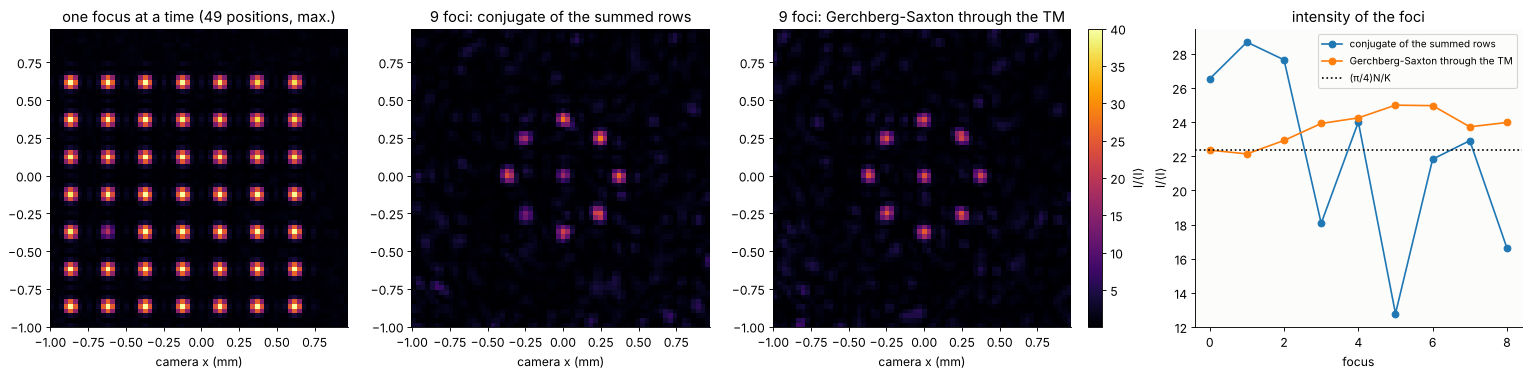

In [9]:
T_meas, _ = ws.measure_transmission_matrix(tm_experiment(0.03, seed=2), N_TM, basis="hadamard")
T_meas /= np.linalg.norm(T_meas, axis=1, keepdims=True)    # remove |r_m| from the rows (Popoff et al.)
grid_c = np.arange(2*ROI)
spots = [(ROI + int(round(12*np.sin(a))), ROI + int(round(12*np.cos(a))))
         for a in np.linspace(0, 2*np.pi, 9)[:-1]] + [(ROI, ROI)]
spot_rows = np.array([i*2*ROI + j for i, j in spots])
K = len(spots)


def camera_image(v):
    return np.abs(T_in @ v)**2/N_TM            # in units of the mean speckle (no reference)


scan = np.zeros(4*ROI*ROI)
for i in range(4, 2*ROI - 4, 8):
    for j in range(4, 2*ROI - 4, 8):
        row = i*2*ROI + j
        scan = np.maximum(scan, camera_image(ws.phase_conjugation(T_meas[row])))
v_pc = ws.phase_conjugation(T_meas[spot_rows].sum(0))
v_gs, _ = ws.tm_gerchberg_saxton(T_meas[spot_rows], np.ones(K), n_iter=100)   # weighted, only the foci

fig, ax = plt.subplots(1, 4, figsize=(19, 4.6), layout="constrained")
show(ax[0], scan.reshape(2*ROI, -1), ext_r, "one focus at a time (49 positions, max.)", vmax=200)
for a, v, title in [(ax[1], v_pc, "{} foci: conjugate of the summed rows".format(K)),
                    (ax[2], v_gs, "{} foci: Gerchberg-Saxton through the TM".format(K))]:
    img = camera_image(v)
    im = show(a, img.reshape(2*ROI, -1), ext_r, title, vmax=40)
    peaks = img[spot_rows]
    print("{:45s} foci: mean {:5.1f}, min {:5.1f}, max {:5.1f}, std/mean {:.2f}; background {:.2f}".format(
        title, peaks.mean(), peaks.min(), peaks.max(), peaks.std()/peaks.mean(),
        np.delete(img, spot_rows).mean()))
    ax[3].plot(np.arange(K), peaks, "o-", label=title.split(": ")[1])
fig.colorbar(im, ax=ax[2], label="I/⟨I⟩")
ax[3].axhline(ws.expected_enhancement(N_TM)/K, color="k", ls=":", label="(π/4)N/K")
ax[3].set_xlabel("focus"); ax[3].set_ylabel("I/⟨I⟩"); ax[3].legend(fontsize=9)
ax[3].set_title("intensity of the foci")
for a in ax[:3]:
    a.set_xlabel("camera x (mm)")

Conjugating the summed rows gives foci whose heights scatter by a few tens
of percent around $\frac{\pi}{4}N/K$: each focus gets a random share,
because the rows interfere on the SLM. The weighted Gerchberg-Saxton loop
through the measured TM (constrained only in the foci) makes them even;
the spread that remains on the camera comes from the noise of the measured
TM, against which the foci were equalized. The background stays at the mean speckle level: with
$N = 256$ degrees of freedom only a few foci can be made with a good
contrast, and an image of $K$ pixels has a contrast of about $N/K$.

## 6. A thick scattering slab with the WPM

A real wall is thick: the light is scattered many times on its way
through. The model is now a slab of a random two-phase medium, a polymer
($n = 1.5$) with inclusions ($n = 1.6$), half of the volume each, with
structures of about 1.5 µm (a thresholded Gaussian random field), and
thicknesses up to 40 µm. The wave propagation method of
[notebook 05](05_WPM.ipynb) (`wpm_propagate_z`) follows the field slice by
slice (1 µm) on a 64 × 64 µm² grid. The SLM is imaged onto the front face
(32 × 32 µm², 16 × 16 segments of 2 µm); a lens behind the slab maps the
far field onto the camera as before. The medium has only two index values,
so the WPM can use its fast "levels" method (two FFTs per slice).

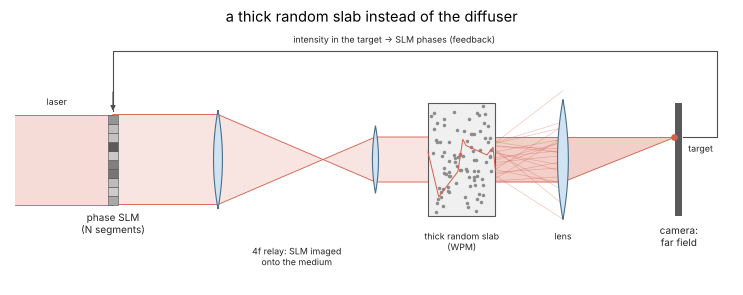

volume fraction of inclusions: 0.500
one WPM run through 30 µm: 0.09 s
speckle contrast behind the slab: 1.028; unscattered light: 3.1e-06 of the clear peak
transmitted power: 0.9866


In [10]:
fig, ax = plt.subplots(figsize=(14, 4.2))
sketch.wavefront_shaping_setup(ax, medium="slab", title="a thick random slab instead of the diffuser")
plt.show()

NS, DXS = 128, 0.5
xs, ys, XS, YS = grid2d(-NS*DXS/2, NS*DXS/2, -NS*DXS/2, NS*DXS/2, NS)
DZ, L_MAX = 1.0, 40
N_POLY, N_INCL = 1.5, 1.6
field3d = ws.random_phase_screen((2*L_MAX, NS, NS), 1.5, 1.0, dx=DXS, rng=3)[1::2]  # 1 µm slices
inclusion = field3d > 0
D_S = 32.0
labels_s = ws.segment_labels(xs, ys, 16, D_S)
aperture_s = (np.abs(XS) < D_S/2) & (np.abs(YS) < D_S/2)
cs = NS//2
print("volume fraction of inclusions: {:.3f}".format(inclusion.mean()))


def slab(L):
    """Index n(X, Y, z) of the first L µm of the medium, and the slice positions."""
    n_slices = int(round(L/DZ))
    n_func = lambda X_, Y_, z: np.where(inclusion[min(int(z/DZ), n_slices - 1)], N_INCL, N_POLY)
    return n_func, np.arange(n_slices + 1)*DZ


def through(u, L, all_planes=False):
    n_func, zs = slab(L)
    out = wpm_propagate_z(n_func, u, xs, ys, zs, WL)
    return out if all_planes else out[-1]


L_SLAB = 30
t0 = time.time()
planes = through(aperture_s.astype(complex), L_SLAB, all_planes=True)
print("one WPM run through {} µm: {:.2f} s".format(L_SLAB, time.time() - t0))
I_far = np.abs(camera(planes[-1]))**2
I_far_clear = np.abs(camera(aperture_s.astype(complex)))**2
roi_s = (slice(cs - 24, cs + 24),)*2
print("speckle contrast behind the slab: {:.3f}; unscattered light: {:.1e} of the clear peak".format(
    I_far[roi_s].std()/I_far[roi_s].mean(), I_far[cs, cs]/I_far_clear[cs, cs]))
print("transmitted power: {:.4f}".format(np.sum(np.abs(planes[-1])**2)/np.sum(aperture_s)))

The TM of the slab is probed segment by segment, 256 WPM runs. With it,
phase conjugation and the feedback algorithms work just as for the thin
diffuser. To see that the focus is not an artefact of the matrix, the
shaped wavefront is sent through the slab once more with the WPM.

TM of the slab (2304 x 256) in 24 s
phase conjugation through the slab: η = 199.7 ± 3.9 over 576 targets (theory 201.3)
CSA through the slab (2 sweeps, 3072 measurements): η = 201.8, phase conjugation 201.8
shaped wavefront, new WPM run: intensity in the target / |t.v|^2 from the TM = 1.000000


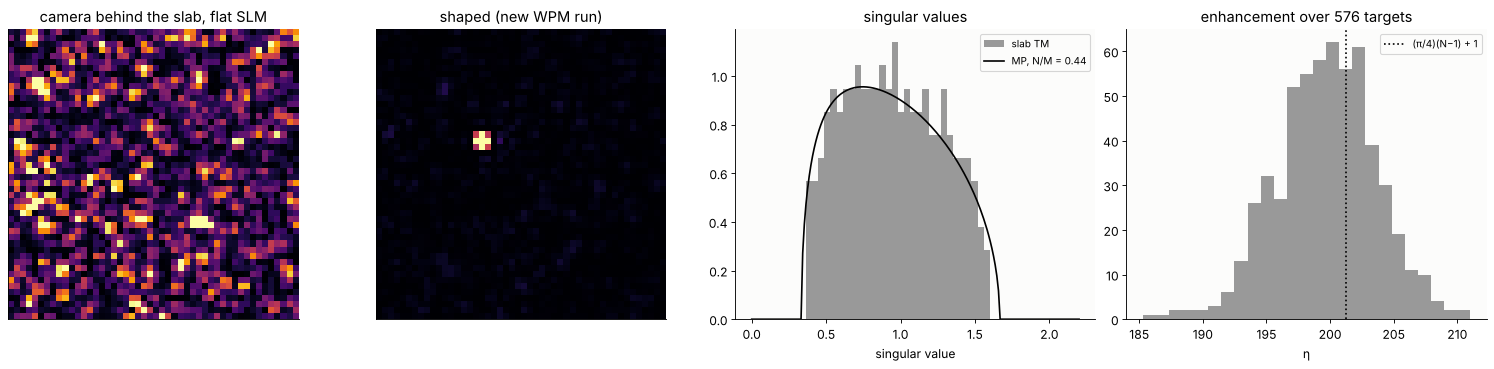

In [11]:
t0 = time.time()
cam_mask_s = np.zeros((NS, NS), bool)
cam_mask_s[roi_s] = True
T_slab = ws.transmission_matrix(lambda u: camera(through(u, L_SLAB)), labels_s, output=cam_mask_s)
print("TM of the slab ({} x {}) in {:.0f} s".format(*T_slab.shape, time.time() - t0))
grain_s = np.nonzero(((np.arange(48)[:, None] % 2 == 0) & (np.arange(48)[None, :] % 2 == 0)).ravel())[0]
eta_s = np.array([ws.enhancement(t, ws.phase_conjugation(t)) for t in T_slab[grain_s]])
print("phase conjugation through the slab: η = {:.1f} ± {:.1f} over {} targets (theory {:.1f})".format(
    eta_s.mean(), eta_s.std(), len(grain_s), ws.expected_enhancement(256)))
sv = np.linalg.svd(T_slab[grain_s]/np.sqrt(np.mean(np.abs(T_slab)**2)*len(grain_s)), compute_uv=False)

tgt_s = (24 + 5, 24 - 7)                                 # in the 48 x 48 window
row_s = tgt_s[0]*48 + tgt_s[1]
t_s = T_slab[row_s]
exp_s = Experiment(t_s)
v_ssa, _ = ws.stepwise_sequential(exp_s, 256, 6, continuous=True, n_sweeps=2)
print("CSA through the slab (2 sweeps, 3072 measurements): η = {:.1f}, phase conjugation {:.1f}".format(
    ws.enhancement(t_s, v_ssa), ws.enhancement(t_s, ws.phase_conjugation(t_s))))

u_shaped = ws.segment_field(ws.phase_conjugation(t_s), labels_s)
I_far_shaped = np.abs(camera(through(u_shaped, L_SLAB)))**2
I_ref_s = I_far[roi_s].mean()
print("shaped wavefront, new WPM run: intensity in the target / |t.v|^2 from the TM = {:.6f}".format(
    I_far_shaped[cs - 24 + tgt_s[0], cs - 24 + tgt_s[1]]/np.abs(t_s @ ws.phase_conjugation(t_s))**2))

fig, ax = plt.subplots(1, 4, figsize=(19, 4.5), layout="constrained")
show(ax[0], I_far[roi_s]/I_ref_s, None, "camera behind the slab, flat SLM", vmax=4)
show(ax[1], I_far_shaped[roi_s]/I_ref_s, None, "shaped (new WPM run)", vmax=60)
for a in ax[:2]:
    a.set_xticks([]); a.set_yticks([])
s_ = np.linspace(0, 2.2, 200)
ax[2].hist(sv, bins=30, density=True, color="0.6", label="slab TM")
ax[2].plot(s_, ws.marchenko_pastur_pdf(s_, 256/len(grain_s)), "k-",
           label="MP, N/M = {:.2f}".format(256/len(grain_s)))
ax[2].set_xlabel("singular value"); ax[2].legend(fontsize=9); ax[2].set_title("singular values")
ax[3].hist(eta_s, bins=25, color="0.6")
ax[3].axvline(ws.expected_enhancement(256), color="k", ls=":", label="(π/4)(N−1) + 1")
ax[3].set_xlabel("η"); ax[3].set_title("enhancement over {} targets".format(len(grain_s)))
ax[3].legend(fontsize=9)

The 30 µm slab scatters as completely as the diffuser (contrast 1, no
ballistic light left), loses nothing (the WPM conserves the power to a
fraction of a percent, the rest leaves at angles beyond the grid), and its
TM behaves like the random matrix of the diffuser: enhancements around
$\frac{\pi}{4}N$, Marchenko-Pastur singular values. The WPM run with the
shaped wavefront reproduces the enhancement of the matrix.

### Digital phase conjugation

The phase conjugate of a TM row can also be computed without the TM: send
the wanted output (a plane wave towards the target direction, the far field
of a point on the camera) backwards through the medium and conjugate it.
In the simulation this is one WPM run from $z = L$ back to $z = 0$; the
row of the TM is the conjugate of this field averaged over each segment
(for a lossless medium the propagator is unitary, $T^\dagger = T^{-1}$).
Experiments do the same with a point source (a guide star such as a
fluorescent bead or the focus of ultrasound) and a camera in front of the
wall, and play the conjugate field back with the SLM.

The same works for a focus at a finite distance: the time-reversed field
of a point 40 µm behind the slab (a converging spherical wave) is sent
backwards through the slab. The side views (the intensity in the $xz$
plane through the focus) show how the light travels: inside the slab the
shaped and the flat wavefront look alike, random speckle in both; behind
it the shaped light converges into a focus.

digital phase conjugation: η = 190.0; from the TM 201.8; phase error rms 0.46 rad


focus 40 µm behind the slab at x = 5.0 µm, y = 0.0 µm; peak / mean speckle there = 189


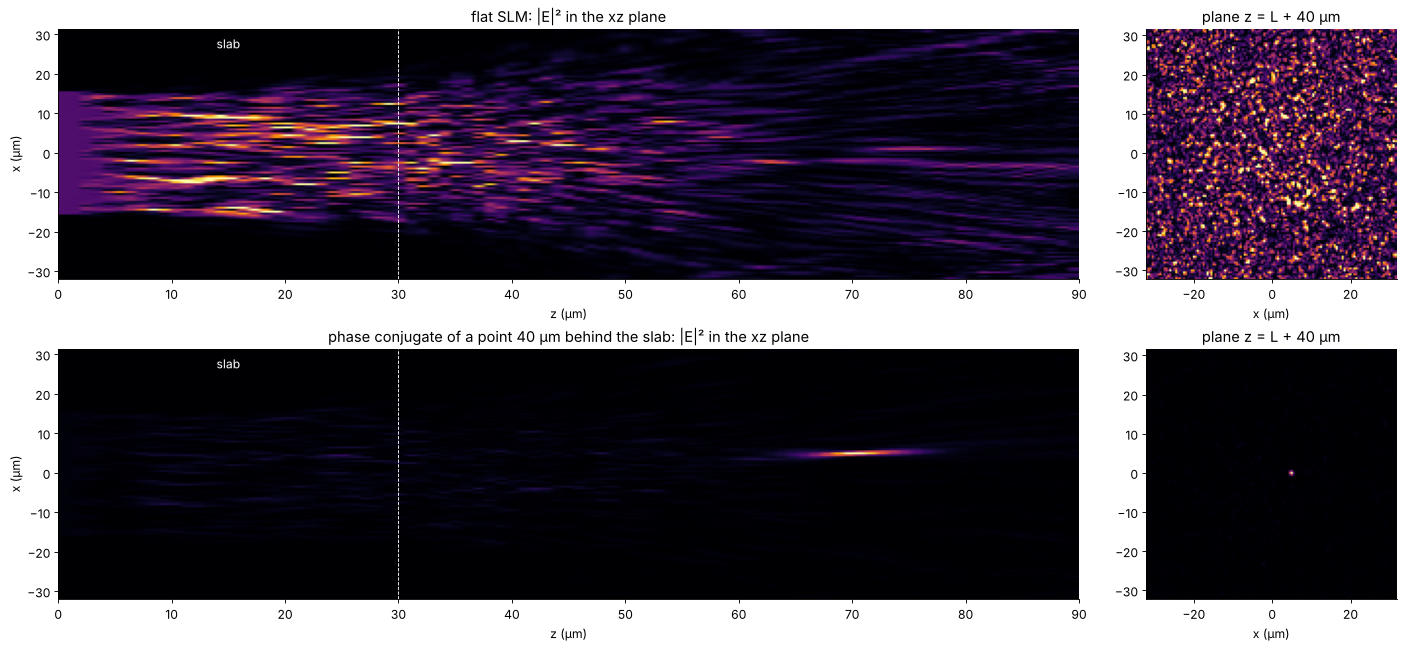

In [12]:
def back_conjugate(L, target_cam):
    """SLM phases from one backward WPM run of the target plane wave."""
    U_t = np.zeros((NS, NS), complex)
    U_t[target_cam] = 1.0
    plane_wave = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(U_t)))
    n_func, zs = slab(L)
    back = wpm_propagate_z(n_func, plane_wave, xs, ys, zs[::-1], WL)[-1]
    ok = labels_s >= 0
    seg = (np.bincount(labels_s[ok], weights=back[ok].real, minlength=256)
           + 1j*np.bincount(labels_s[ok], weights=back[ok].imag, minlength=256))
    return np.exp(1j*np.angle(seg))


target_cam = (cs - 24 + tgt_s[0], cs - 24 + tgt_s[1])
v_dpc = back_conjugate(L_SLAB, target_cam)
print("digital phase conjugation: η = {:.1f}; from the TM {:.1f}; phase error rms {:.2f} rad".format(
    ws.enhancement(t_s, v_dpc), ws.enhancement(t_s, ws.phase_conjugation(t_s)),
    np.std(np.angle(v_dpc*np.exp(1j*np.angle(t_s))))))

# a focus at a finite distance: a point 40 µm behind the slab, 5 µm off the axis
Z_F, X_F = 40.0, 5.0
point = np.zeros((NS, NS), complex)
point[cs, cs + int(X_F/DXS)] = 1.0
converging = np.conj(rayleigh_sommerfeld_I_TF(point, xs, ys, Z_F, WL)[0])   # time reversed point source
n_func, zs = slab(L_SLAB)
back = wpm_propagate_z(n_func, converging, xs, ys, zs[::-1], WL)[-1]
ok = labels_s >= 0
seg = (np.bincount(labels_s[ok], weights=back[ok].real, minlength=256)
       + 1j*np.bincount(labels_s[ok], weights=back[ok].imag, minlength=256))
u_point = ws.segment_field(np.exp(1j*np.angle(seg)), labels_s)

z_free = np.arange(1, 61)*1.0
fig, ax = plt.subplots(2, 2, figsize=(18, 8), layout="constrained", gridspec_kw={"width_ratios": [3, 1]})
z_all = np.r_[np.arange(L_SLAB + 1)*DZ, L_SLAB + z_free]
for k, (u_in, title) in enumerate([(aperture_s.astype(complex), "flat SLM"),
                                   (u_point, "phase conjugate of a point 40 µm behind the slab")]):
    pl = through(u_in, L_SLAB, all_planes=True)
    after = rayleigh_sommerfeld_I_TF_planes(pl[-1], xs, ys, z_free, WL)[0]
    side = np.vstack([np.abs(pl[:, cs, :])**2, np.abs(after[:, cs, :])**2])
    focal = np.abs(after[int(Z_F) - 1])**2
    a = ax[k, 0]
    a.imshow(side.T, extent=[z_all[0], z_all[-1], xs[0], xs[-1]], aspect="auto", cmap="inferno",
             vmax=np.percentile(side, 99.7) if k == 0 else side[L_SLAB + int(Z_F)].max())
    a.axvline(L_SLAB, color="w", ls="--", lw=0.8)
    a.text(L_SLAB/2, xs[-1] - 5, "slab", color="w", ha="center")
    a.set_xlabel("z (µm)"); a.set_ylabel("x (µm)"); a.set_title(title + ": |E|² in the xz plane")
    show(ax[k, 1], focal/focal.mean(), extent(xs), "plane z = L + 40 µm", vmax=None if k else 4)
    ax[k, 1].set_xlabel("x (µm)")
    if k:
        I_bg = np.mean(np.abs(rayleigh_sommerfeld_I_TF(through(aperture_s.astype(complex), L_SLAB), xs, ys,
                                                       Z_F, WL)[0])[cs - 32:cs + 32, cs - 32:cs + 32]**2)
        i_max = np.unravel_index(np.argmax(focal), focal.shape)
        print("focus 40 µm behind the slab at x = {:.1f} µm, y = {:.1f} µm; peak / mean speckle there = {:.0f}".format(
            xs[i_max[1]], ys[i_max[0]], focal.max()/I_bg))

One backward run gives 94 % of the enhancement of the measured TM: the
WPM is not exactly unitary (the index steps of the two-phase medium and the
sampling make the backward run differ slightly from the inverse of the
forward run), and the phase error is a fraction of a radian. The focus
behind the slab appears where it was asked for, with an enhancement close
to $\frac{\pi}{4}N$ over the speckle in that plane.

### The optical memory effect

Once the wavefront for one focus is found, tilting it a little (with a
galvo mirror in front of the SLM) moves the focus by the same angle
without a new optimization, as long as the medium "remembers" the tilt.
Behind a thin diffuser the memory is perfect: tilting the incident field
only shifts the far field. A thick slab forgets: the tilted light takes
different paths through the medium, and the focus fades. This **optical
memory effect** (Feng, Kane, Lee and Stone 1988; Freund, Rosenbluh and
Feng 1988) is what allows scanning a focus, or imaging, through a thin
layer such as the skull of a mouse or a diffuser in front of a camera.

For each thickness the shaped wavefront comes from one backward WPM run
(above), and then a tilt $\Delta\theta$ is added and the slab traversed
forwards; the plot shows the intensity of the moved focus relative to the
untilted one. For a diffusive medium (light scattered in all directions)
the correlation falls as $[k\Delta\theta L/\sinh(k\Delta\theta L)]^2$,
on the scale $\Delta\theta \sim \lambda/(2\pi L)$. The medium here scatters
mostly forwards, and the light keeps a memory over a much larger range,
set by the size of the structures rather than by the wavelength: the
focus fades when the lateral shift $\Delta\theta L$ of the paths inside
the medium reaches about the size of the inclusions.

thickness   η(0)   tilt of half intensity (mrad)   tilt x L (µm)
     0 µm     221            nan                       nan


    10 µm     197          192.4                      1.92


    20 µm     188           61.8                      1.24


    30 µm     203           31.5                      0.94


    40 µm     197           24.1                      0.96


Text(0.5, 1.0, 'against the lateral shift of the paths')

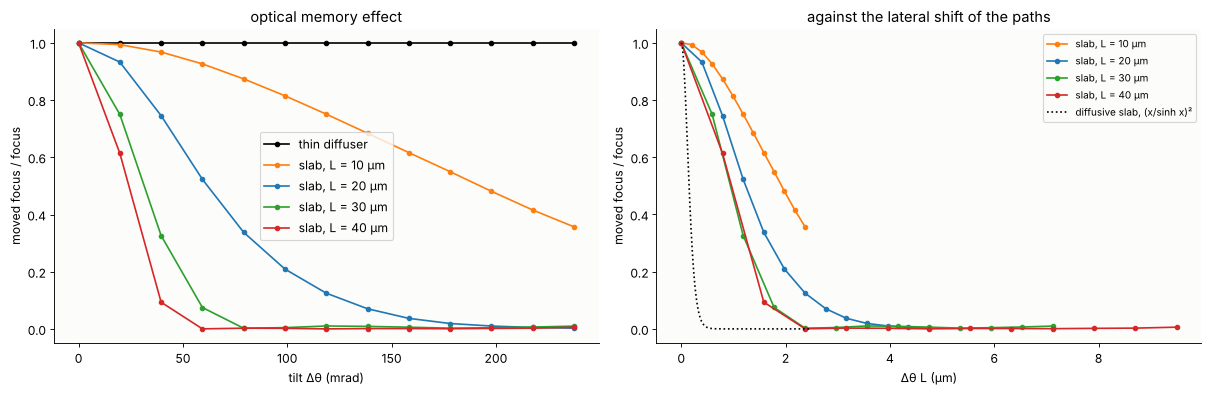

In [13]:
shifts = np.arange(0, 25, 2)                             # camera samples
dtheta = shifts*WL/(NS*DXS)                              # tilt in air (rad)
thin = np.exp(1j*ws.random_phase_screen((NS, NS), 1.5, 2*np.pi, dx=DXS, rng=4))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
print("thickness   η(0)   tilt of half intensity (mrad)   tilt x L (µm)")
for L, colour in [(0, "k"), (10, "C1"), (20, "C0"), (30, "C2"), (40, "C3")]:
    if L == 0:
        t_thin = ws.transmission_matrix(lambda u: camera(u*thin), labels_s,
                                        output=lambda U: U[target_cam])[0]
        v, prop = ws.phase_conjugation(t_thin), (lambda u: u*thin)
    else:
        v, prop = back_conjugate(L, target_cam), (lambda u, L=L: through(u, L))
    u0 = ws.segment_field(v, labels_s)
    I_shift = []
    for s_ in shifts:
        I_cam = np.abs(camera(prop(u0*np.exp(2j*np.pi*s_*XS/(NS*DXS)))))**2
        I_shift.append(I_cam[target_cam[0], target_cam[1] + s_])
    I_shift = np.array(I_shift)/I_shift[0]
    I_bg = np.mean(np.abs(camera(prop(aperture_s.astype(complex))))[roi_s]**2)
    eta0 = np.abs(camera(prop(u0)))[target_cam]**2/I_bg
    half = np.interp(0.5, I_shift[::-1], dtheta[::-1]) if I_shift.min() < 0.5 else np.nan
    print("{:6d} µm  {:6.0f}   {:12.1f}                {:10.2f}".format(L, eta0, 1e3*half, half*L))
    label = "thin diffuser" if L == 0 else "slab, L = {} µm".format(L)
    ax[0].plot(1e3*dtheta, I_shift, "o-", color=colour, ms=4, label=label)
    if L:
        ax[1].plot(dtheta*L, I_shift, "o-", color=colour, ms=4, label=label)
ax[0].set_xlabel("tilt Δθ (mrad)"); ax[0].set_ylabel("moved focus / focus")
ax[0].legend(); ax[0].set_title("optical memory effect")
xx = np.linspace(1e-6, 2.5, 200)
k_n = 2*np.pi*N_POLY/WL
ax[1].plot(xx, (k_n*xx/N_POLY/np.sinh(k_n*xx/N_POLY))**2, "k:", label="diffusive slab, (x/sinh x)²")
ax[1].set_xlabel("Δθ L (µm)"); ax[1].set_ylabel("moved focus / focus")
ax[1].legend(fontsize=9); ax[1].set_title("against the lateral shift of the paths")

The thin diffuser keeps the focus at full strength over the whole range.
For the slabs the memory range shrinks with the thickness: the 30 and 40 µm
slabs fall onto one curve against $\Delta\theta L$ and lose half the focus
at $\Delta\theta L \approx 1$ µm, about the size of the inclusions. The
thinner slabs, in which the light has been scattered fewer times, remember
a little longer than this $1/L$ law ($\Delta\theta L \approx 1.2$ µm at
20 µm, 1.9 µm at 10 µm). A diffusive medium of the same thickness would
forget about ten times faster (dotted, with the angle inside the polymer):
the forward scattering of tissue-like media is what makes the memory effect
usable there.

## 7. A multimode fibre

A multimode fibre scrambles light like a scattering wall: an image at the
input arrives as speckle at the output, because the guided modes travel with
different propagation constants and, in a bent or long fibre, exchange
power. Unlike the wall, the fibre has only $M$ guided modes. Wavefront
shaping at the input then makes a focus at the output facet, which is the
principle of lensless endoscopes thinner than a hair.

The fibre is a step-index fibre with a core of 28 µm diameter and
$\mathrm{NA} = 0.1$, $V = 13.9$ at 633 nm, with the LP modes of
[notebook 09](09_mode_analysis.ipynb) (`modes.lp_modes`, both orientations
of every mode with $l > 0$: $M = 51$ scalar modes in one polarization). The
SLM is imaged onto the core, the input field couples into the modes by the
overlap integrals, a random unitary matrix (`ws.random_unitary()`) models
the strong mode coupling of a long fibre including the modal phases, and
the output field is the sum of the modes at the far facet:

$$T = \Psi_\mathrm{out}\, U\, C, \qquad C_{kn} = \int \psi_k^*\, s_n\, dA.$$

The contrast of the focus is measured against the mean intensity over the
core at the output, with the same shaped input.

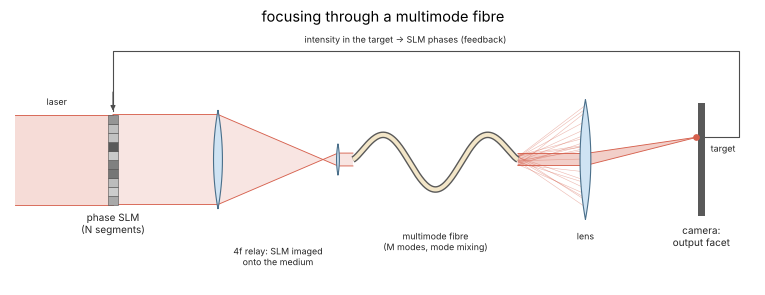

V = 13.90: 28 LP modes, M = 51 scalar modes (V²/4 = 48); mode orthogonality error 5.4e-06


N =     4: contrast phase only   3.2, amplitude and phase   3.7; power coupled from a single segment 0.81
N =    16: contrast phase only  12.4, amplitude and phase  15.0; power coupled from a single segment 0.73
N =    36: contrast phase only  26.1, amplitude and phase  31.5; power coupled from a single segment 0.62
N =    64: contrast phase only  37.4, amplitude and phase  44.3; power coupled from a single segment 0.50
N =   144: contrast phase only  44.2, amplitude and phase  49.3; power coupled from a single segment 0.25
N =   256: contrast phase only  45.5, amplitude and phase  49.9; power coupled from a single segment 0.17
N =   576: contrast phase only  46.0, amplitude and phase  50.1; power coupled from a single segment 0.07
N =  1024: contrast phase only  46.1, amplitude and phase  50.2; power coupled from a single segment 0.04
N =  2304: contrast phase only  46.2, amplitude and phase  50.2; power coupled from a single segment 0.01


In [14]:
fig, ax = plt.subplots(figsize=(14, 4.2))
sketch.wavefront_shaping_setup(ax, medium="fibre", title="focusing through a multimode fibre")
plt.show()

A_CORE, NA_F = 14.0, 0.1
V_F = 2*np.pi*A_CORE*NA_F/WL
lp = modes.lp_modes(V_F)
NF, DXF = 256, 0.25
xf, yf, XF, YF = grid2d(-NF*DXF/2, NF*DXF/2, -NF*DXF/2, NF*DXF/2, NF)
mode_fields, mode_names = [], []
for m in lp:
    for orientation in (["cos"] if m.l == 0 else ["cos", "sin"]):
        mode_fields.append(m.field(xf, yf, A_CORE, orientation).ravel())
        mode_names.append((m.l, m.m, orientation))
Psi = np.array(mode_fields)                                # (M, pixels), unit power
M_F = len(Psi)
U_F = ws.random_unitary(M_F, rng=5)
core = (XF**2 + YF**2 < A_CORE**2).ravel()
print("V = {:.2f}: {} LP modes, M = {} scalar modes (V²/4 = {:.0f}); mode orthogonality error {:.1e}".format(
    V_F, len(lp), M_F, V_F**2/4, np.abs(Psi @ Psi.conj().T*DXF**2 - np.eye(M_F)).max()))


def fibre_tm(n):
    """TM from n x n SLM segments on the core square to the output samples."""
    lab = ws.segment_labels(xf, yf, n, 2*A_CORE).ravel()
    ok = lab >= 0
    C = np.array([np.bincount(lab[ok], weights=np.conj(p[ok]).real, minlength=n*n)
                  + 1j*np.bincount(lab[ok], weights=np.conj(p[ok]).imag, minlength=n*n) for p in Psi])*DXF**2
    return U_F @ C, lab                                    # mode amplitudes at the output per segment


rng_f = np.random.default_rng(6)
targets_f = rng_f.choice(np.nonzero(XF.ravel()**2 + YF.ravel()**2 < (0.8*A_CORE)**2)[0], 60, replace=False)
n_values = [2, 4, 6, 8, 12, 16, 24, 32, 48]
contrast = {"phase": [], "full": []}
coupled = []
for n in n_values:
    Tm, lab = fibre_tm(n)
    coupled.append(np.mean(np.sum(np.abs(Tm)**2, 0))/(DXF**2*np.sum(lab == 0)))
    for modulation in contrast:
        cs_ = []
        for p in targets_f:
            t = Psi[:, p] @ Tm
            out = np.abs(Psi.T @ (Tm @ ws.phase_conjugation(t, modulation)))**2
            cs_.append(out[p]/out[core].mean())
        contrast[modulation].append(np.mean(cs_))
N_f = np.array(n_values)**2
for n, N, cp, cf, cpl in zip(n_values, N_f, contrast["phase"], contrast["full"], coupled):
    print("N = {:5d}: contrast phase only {:5.1f}, amplitude and phase {:5.1f}; "
          "power coupled from a single segment {:.2f}".format(N, cp, cf, cpl))

Text(0.5, 1.0, 'contrast of the focus at the output')

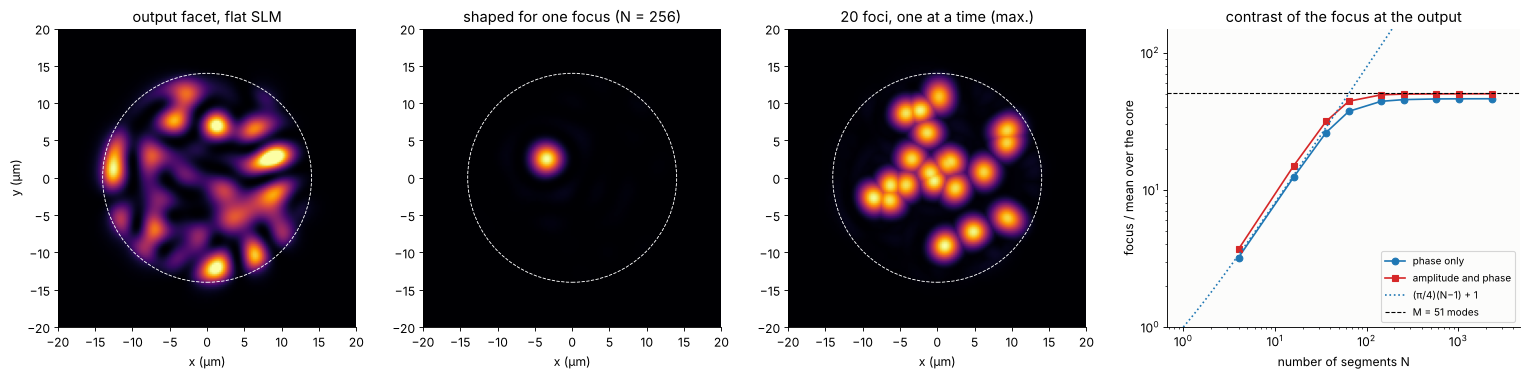

In [15]:
Tm, lab = fibre_tm(16)
flat = np.ones(256)
out_flat = (Psi.T @ (Tm @ flat)).reshape(NF, NF)
p0 = targets_f[0]
v_f = ws.phase_conjugation(Psi[:, p0] @ Tm)
out_focus = (Psi.T @ (Tm @ v_f)).reshape(NF, NF)
scan_f = np.zeros(NF*NF)
for p in targets_f[:20]:
    o = np.abs(Psi.T @ (Tm @ ws.phase_conjugation(Psi[:, p] @ Tm)))**2
    scan_f = np.maximum(scan_f, o/o[core].mean())

fig, ax = plt.subplots(1, 4, figsize=(19, 4.6), layout="constrained")
ext_f = extent(xf)
I_flat_f = np.abs(out_flat)**2
I_focus_f = np.abs(out_focus)**2
show(ax[0], I_flat_f/I_flat_f.ravel()[core].mean(), ext_f, "output facet, flat SLM", vmax=4)
show(ax[1], I_focus_f/I_focus_f.ravel()[core].mean(), ext_f, "shaped for one focus (N = 256)")
show(ax[2], scan_f.reshape(NF, NF), ext_f, "20 foci, one at a time (max.)")
for a in ax[:3]:
    a.add_patch(plt.Circle((0, 0), A_CORE, fill=False, color="w", ls="--", lw=0.8))
    a.set_xlim(-20, 20); a.set_ylim(-20, 20); a.set_xlabel("x (µm)")
ax[0].set_ylabel("y (µm)")
NN = np.logspace(0, 3.5, 100)
ax[3].plot(N_f, contrast["phase"], "o-", color="C0", label="phase only")
ax[3].plot(N_f, contrast["full"], "s-", color="C3", label="amplitude and phase")
ax[3].plot(NN, ws.expected_enhancement(NN), "C0:", label="(π/4)(N−1) + 1")
ax[3].axhline(M_F, color="k", ls="--", lw=1, label="M = {} modes".format(M_F))
ax[3].set_xscale("log"); ax[3].set_yscale("log"); ax[3].set_ylim(1, 150)
ax[3].set_xlabel("number of segments N"); ax[3].set_ylabel("focus / mean over the core")
ax[3].legend(fontsize=9); ax[3].set_title("contrast of the focus at the output")

For few segments the fibre behaves like the wall, with a contrast near
$\frac{\pi}{4}N$. Beyond $N \approx M$ the contrast saturates at the number
of modes: the output field has only $M$ degrees of freedom, and the best
focus is the projection of a point onto the guided modes, which contains
$1/M$ of the guided power on average. With full control the limit is $M$
itself; phase-only gets close to it once $N \gg M$. More segments still
help in another way: they couple the light better, because the shaped
input matches the modes, while a single small segment sends most of its
light outside the NA (last column of the table).

The size of the focus is set by the NA: the focus of all modes together is
the kernel $\sum_k \psi_k(\mathbf{r}_0)^*\psi_k(\mathbf{r})$, which near the
axis is close to the Airy pattern $[2J_1(v)/v]^2$, $v = 2\pi\,\mathrm{NA}\,r/\lambda$.

FWHM of the focus: 3.12 µm (Airy: 0.514 λ/NA = 3.25 µm)


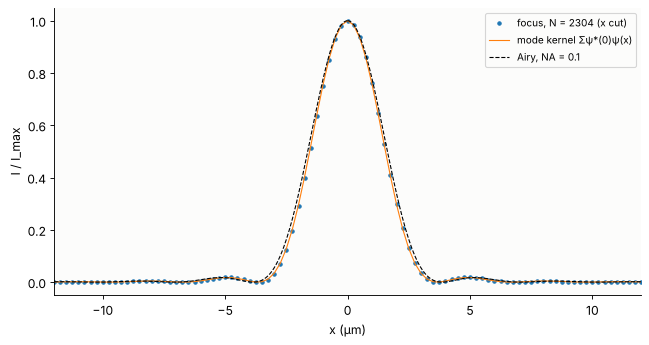

In [16]:
p_c = np.argmin(XF.ravel()**2 + YF.ravel()**2)
Tm48, _ = fibre_tm(48)
v_c = ws.phase_conjugation(Psi[:, p_c] @ Tm48, "full")
I_c = (np.abs(Psi.T @ (Tm48 @ v_c))**2).reshape(NF, NF)
kernel = (np.abs(Psi.T @ Psi[:, p_c].conj())**2).reshape(NF, NF)
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
r_ = np.linspace(1e-6, 12, 300)
v_ = 2*np.pi*NA_F*r_/WL
ax.plot(xf, I_c[NF//2]/I_c.max(), "o", ms=3, label="focus, N = 2304 (x cut)")
ax.plot(xf, kernel[NF//2]/kernel.max(), "-", color="C1", lw=1, label="mode kernel Σψ*(0)ψ(x)")
ax.plot(r_, (2*j1(v_)/v_)**2, "k--", lw=1, label="Airy, NA = 0.1")
ax.plot(-r_, (2*j1(v_)/v_)**2, "k--", lw=1)
ax.set_xlim(-12, 12); ax.set_xlabel("x (µm)"); ax.set_ylabel("I / I_max"); ax.legend(fontsize=9)
fwhm = 2*np.interp(0.5, (I_c[NF//2, NF//2:]/I_c.max())[::-1], xf[NF//2:][::-1])
print("FWHM of the focus: {:.2f} µm (Airy: 0.514 λ/NA = {:.2f} µm)".format(fwhm, 0.514*WL/NA_F))

The focus at the output facet has the width of the Airy spot of the fibre
NA, to within 4 %: the fibre acts as a lens of its NA at its far end.

## Summary

- A strong diffuser gives fully developed speckle: exponential intensity
  statistics, contrast 1, grains of the size of the diffraction spot of the
  illuminated aperture.
- The transmission matrix of a scattering medium is a random matrix with
  circular Gaussian elements; its singular values follow the
  Marchenko-Pastur law as long as the output samples are uncorrelated (one
  per grain). `ws.transmission_matrix()` probes any linear propagator,
  `ws.marchenko_pastur_pdf()` gives the law.
- With the TM the focus enhancement is $N$ for full control,
  $\frac{\pi}{4}(N-1)+1$ for phase-only, $1 + (N-1)/\pi$ for binary phase
  and $1 + (N-1)/2\pi$ for binary amplitude modulation
  (`ws.phase_conjugation()`, `ws.enhancement()`,
  `ws.expected_enhancement()`), all confirmed to about 1 % (binary
  amplitude with the best reference phase a little above). The focus is
  one speckle grain; the background stays at the mean speckle level.
- Feedback algorithms reach the same focus with only the target intensity
  (`ws.stepwise_sequential()`, `ws.partitioning()`): SSA is nearly exact
  without noise but drowns in noise of the size of the speckle signal, CSA
  recovers as the focus grows, RPA hardly notices the noise; in a medium
  that changes, the sequential algorithms keep the higher focus.
- The TM is measured with $4N$ camera frames against an internal reference
  (`ws.measure_transmission_matrix()`); the Hadamard basis tolerates about
  ten times more camera noise than the canonical one. Several foci share
  the enhancement, $\approx \frac{\pi}{4}N/K$ each; a Gerchberg-Saxton loop
  through the TM (`ws.tm_gerchberg_saxton()`, built on `ifta.IFTABase`)
  makes them equal.
- A thick random slab simulated with the WPM behaves the same: the focus
  appears only behind the slab. Digital phase conjugation from one backward
  WPM run gives 94 % of the TM optimum, also for a focus at a finite
  distance behind the slab. The memory effect shrinks with the thickness;
  in a forward scattering medium the focus fades when $\Delta\theta L$
  reaches about the size of the structures, far more slowly than in a
  diffusive medium.
- A multimode fibre (LP modes from `modes.lp_modes()`, random mode coupling
  from `ws.random_unitary()`) gives a focus at the output whose contrast
  saturates at the number of modes $M$, with the Airy width of the NA.

## References

- I. M. Vellekoop and A. P. Mosk, "Focusing coherent light through opaque strongly scattering media", Opt. Lett. 32, 2309-2311 (2007).
- I. M. Vellekoop and A. P. Mosk, "Phase control algorithms for focusing light through turbid media", Opt. Commun. 281, 3071-3080 (2008).
- S. M. Popoff, G. Lerosey, R. Carminati, M. Fink, A. C. Boccara and S. Gigan, "Measuring the transmission matrix in optics: an approach to the study and control of light propagation in disordered media", Phys. Rev. Lett. 104, 100601 (2010).
- S. Popoff, G. Lerosey, M. Fink, A. C. Boccara and S. Gigan, "Image transmission through an opaque material", Nat. Commun. 1, 81 (2010).
- D. Akbulut, T. J. Huisman, E. G. van Putten, W. L. Vos and A. P. Mosk, "Focusing light through random photonic media by binary amplitude modulation", Opt. Express 19, 4017-4029 (2011).
- I. M. Vellekoop, "Feedback-based wavefront shaping", Opt. Express 23, 12189-12206 (2015).
- A. P. Mosk, A. Lagendijk, G. Lerosey and M. Fink, "Controlling waves in space and time for imaging and focusing in complex media", Nat. Photonics 6, 283-292 (2012).
- S. Rotter and S. Gigan, "Light fields in complex media: mesoscopic scattering meets wave control", Rev. Mod. Phys. 89, 015005 (2017).
- S. Feng, C. Kane, P. A. Lee and A. D. Stone, "Correlations and fluctuations of coherent wave transmission through disordered media", Phys. Rev. Lett. 61, 834-837 (1988).
- I. Freund, M. Rosenbluh and S. Feng, "Memory effects in propagation of optical waves through disordered media", Phys. Rev. Lett. 61, 2328-2331 (1988).
- S. Schott, J. Bertolotti, J.-F. Léger, L. Bourdieu and S. Gigan, "Characterization of the angular memory effect of scattered light in biological tissues", Opt. Express 23, 13505-13516 (2015).
- M. Plöschner, T. Tyc and T. Čižmár, "Seeing through chaos in multimode fibres", Nat. Photonics 9, 529-535 (2015).
- T. Čižmár and K. Dholakia, "Exploiting multimode waveguides for pure fibre-based imaging", Nat. Commun. 3, 1027 (2012).
- V. A. Marchenko and L. A. Pastur, "Distribution of eigenvalues for some sets of random matrices", Math. USSR-Sbornik 1, 457-483 (1967).
- J. W. Goodman, *Speckle Phenomena in Optics*, 2nd ed., SPIE Press (2020).

In [17]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 102 s
